# Estudo de Caso 8.X1 — Estabilidade Numérica de Esquemas de Diferenças Finitas: Explícito, Implícito e Crank-Nicolson

| Campo | Detalhe |
|:------|:--------|
| **Capítulo Associado** | Capítulo 8 — Transferência de Calor em Solos |
| **Nível** | Pós-Graduação |
| **Tempo estimado** | 60 minutos |
| **Autor** | Jader Lugon Junior |
| **Método numérico** | Diferenças Finitas — Explícito, Implícito e Crank-Nicolson |
| **Bibliografia** | Lugon Jr. et al. (2026), Cap. 8, Seções 8.4–8.6; Incropera et al. (2017), Cap. 5; Smith (1985), Cap. 2 |

---

## 📋 Resumo

Analisamos a estabilidade de três esquemas de Diferenças Finitas para a equação de calor 1D transiente: Explícito (Euler para frente), Implícito (Euler para trás) e Crank-Nicolson. Demonstramos a condição CFL ($r \leq 0{,}5$) do esquema explícito, a estabilidade incondicional do implícito e a precisão de segunda ordem do Crank-Nicolson. A análise de von Neumann é validada numericamente, e o algoritmo de Thomas é implementado para resolução eficiente de sistemas tridiagonais.

---

## 🎯 Objetivos de Aprendizagem

Ao final deste estudo de caso, o leitor será capaz de:

1. **Implementar** os esquemas Explícito, Implícito e Crank-Nicolson para a equação de calor 1D
2. **Demonstrar** numericamente a condição CFL ($r \leq 0{,}5$) do esquema explícito
3. **Aplicar** o algoritmo de Thomas para resolução de sistemas tridiagonais
4. **Comparar** a precisão e o custo computacional dos três esquemas
5. **Analisar** a estabilidade pelo número de Fourier $r = \alpha \Delta t / (\Delta z)^2$
6. **Avaliar** o erro de truncamento e a ordem de convergência de cada esquema

---
## ⚙️ Seção 0: Configuração Inicial

In [1]:
# ============================================================
# CONFIGURAÇÃO INICIAL — Importação de bibliotecas
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.linalg import solve_banded
from IPython.display import display, Markdown
import time

# Configuração de estilo dos gráficos (padrão do guia)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

print('✅ Ambiente configurado com sucesso')
print(f'📦 NumPy {np.__version__} | Matplotlib {plt.matplotlib.__version__}')

✅ Ambiente configurado com sucesso
📦 NumPy 2.3.5 | Matplotlib 3.10.6


---
## 🌡️ Seção 1: Parâmetros do Problema

### Contexto Físico

A equação de calor 1D transiente descreve a evolução temporal da temperatura em um meio sólido:

$$\frac{\partial T}{\partial t} = \alpha \frac{\partial^2 T}{\partial z^2}$$

A discretização temporal pode ser feita de três formas:
- **Explícito:** $T^{n+1}$ calculado a partir de $T^n$ (sem sistema linear)
- **Implícito:** $T^{n+1}$ obtido por resolução de sistema linear
- **Crank-Nicolson:** média dos dois (implícito centrado no tempo)

A escolha do esquema determina a **estabilidade**, a **precisão** e o **custo computacional** da simulação.

> 💡 **Observação:** Este é um estudo de caso **metodológico**: o foco não é um problema físico específico, mas a análise comparativa dos esquemas numéricos. Os resultados são aplicáveis a qualquer problema de difusão (calor, massa, poluentes).

### Tabela de Parâmetros

| Parâmetro | Símbolo | Valor | Unidade |
|:----------|:-------:|------:|:-------:|
| **Propriedades do solo** | | | |
| Difusividade térmica | $\alpha$ | 6,17×10⁻⁷ | m²/s |
| **Domínio e discretização** | | | |
| Comprimento do domínio | $L$ | 0,5 | m |
| Número de nós | $N$ | 51 | – |
| Espaçamento espacial | $\Delta z$ | 0,01 | m |
| **Condições de contorno** | | | |
| Temperatura na superfície | $T(0,t)$ | 20 | °C |
| Temperatura na base | $T(L,t)$ | 30 | °C |
| **Condição inicial** | | | |
| Degrau de temperatura | $T_0$ | 20 → 30 °C em $z = L/2$ | – |

In [2]:
# ============================================================
# PARÂMETROS DO PROBLEMA
# ============================================================

# Propriedades do solo (franco-arenoso)
alpha = 6.17e-7       # Difusividade térmica [m²/s]

# Domínio e discretização espacial
L = 0.5               # Comprimento do domínio [m]
N = 51                # Número de nós [-]
z = np.linspace(0, L, N)   # Posições [m]
dz = L / (N - 1)      # Espaçamento espacial [m]

# Condições de contorno (Dirichlet)
T_esq = 20.0          # Temperatura na superfície [°C]
T_dir = 30.0          # Temperatura na base [°C]

# Condição inicial: degrau de temperatura
T_init = np.full(N, T_esq)
T_init[N//2:] = T_dir   # Degrau em z = L/2

# Passos de tempo a testar
dt_values = [5.0, 40.0, 80.0, 160.0]   # [s]
N_steps = 100         # Número de passos temporais

print('📏 Parâmetros do Problema:')
print(f'  • α = {alpha:.2e} m²/s')
print(f'  • L = {L} m, N = {N} nós, Δz = {dz*100:.1f} cm')
print(f'  • T_esq = {T_esq}°C, T_dir = {T_dir}°C')
print(f'  • Condição inicial: degrau em z = {L/2} m')
print(f'  • Passos de tempo: {dt_values} s')

📏 Parâmetros do Problema:
  • α = 6.17e-07 m²/s
  • L = 0.5 m, N = 51 nós, Δz = 1.0 cm
  • T_esq = 20.0°C, T_dir = 30.0°C
  • Condição inicial: degrau em z = 0.25 m
  • Passos de tempo: [5.0, 40.0, 80.0, 160.0] s


---
## 🔬 Seção 2: Verificação — Solução Analítica de Referência

Para validar os esquemas numéricos, usamos a solução analítica da equação de calor com condição inicial de degrau e condições de contorno Dirichlet.

A solução é obtida por separação de variáveis (série de Fourier):

$$T(z,t) = T_{esq} + (T_{dir} - T_{esq})\frac{z}{L} + \sum_{n=1}^{\infty} B_n \sin\left(\frac{n\pi z}{L}\right) e^{-\alpha (n\pi/L)^2 t}$$

> 📖 **Referência:** Incropera et al. (2017), Cap. 5, Seção 5.5; Lugon Jr. et al. (2026), Cap. 8, Seção 8.3.

In [4]:
# ============================================================
# SOLUÇÃO ANALÍTICA (SÉRIE DE FOURIER)
# ============================================================

def solucao_analitica(z_arr, t, T_esq, T_dir, alpha, L, N_termos=100):
    """
    Solução analítica da equação de calor 1D com degrau inicial.

    Parameters
    ----------
    z_arr : ndarray
        Posições espaciais [m].
    t : float
        Tempo [s].
    T_esq : float
        Temperatura na superfície [°C].
    T_dir : float
        Temperatura na base [°C].
    alpha : float
        Difusividade térmica [m²/s].
    L : float
        Comprimento do domínio [m].
    N_termos : int
        Número de termos da série de Fourier.

    Returns
    -------
    ndarray
        Perfil de temperatura T(z,t) [°C].
    """
    # Solução de regime permanente (linear)
    T_ss = T_esq + (T_dir - T_esq) * z_arr / L

    # Coeficientes da série (condição inicial: degrau)
    T_trans = np.zeros_like(z_arr)
    f_init = T_init - T_ss  # Condição inicial menos regime permanente

    for n in range(1, N_termos + 1):
        # Coeficiente B_n por integração numérica
        B_n = 2.0 / L * np.trapezoid(f_init * np.sin(n * np.pi * z_arr / L), z_arr)
        T_trans += B_n * np.sin(n * np.pi * z_arr / L) * np.exp(-alpha * (n * np.pi / L)**2 * t)

    return T_ss + T_trans


# Verificação rápida
t_teste = 1000.0   # [s]
T_ana_teste = solucao_analitica(z, t_teste, T_esq, T_dir, alpha, L)

print('🔬 VERIFICAÇÃO — SOLUÇÃO ANALÍTICA')
print('=' * 50)
print(f'  • T(z=0, t={t_teste}) = {T_ana_teste[0]:.2f}°C (deve ser {T_esq})')
print(f'  • T(z=L, t={t_teste}) = {T_ana_teste[-1]:.2f}°C (deve ser {T_dir})')
print(f'  • T(z=L/2, t={t_teste}) = {T_ana_teste[N//2]:.2f}°C')
print(f'\n✅ Solução analítica implementada e verificada')

🔬 VERIFICAÇÃO — SOLUÇÃO ANALÍTICA
  • T(z=0, t=1000.0) = 20.00°C (deve ser 20.0)
  • T(z=L, t=1000.0) = 30.00°C (deve ser 30.0)
  • T(z=L/2, t=1000.0) = 25.57°C

✅ Solução analítica implementada e verificada


---
## 📐 Seção 3: Formulação Matemática

### 3.1 Equação de Calor 1D

$$\frac{\partial T}{\partial t} = \alpha \frac{\partial^2 T}{\partial z^2}$$

### 3.2 Número de Fourier

$$r = \frac{\alpha \Delta t}{(\Delta z)^2}$$

### 3.3 Esquema Explícito (Euler para frente)

$$T_i^{n+1} = T_i^n + r\left(T_{i+1}^n - 2T_i^n + T_{i-1}^n\right)$$

- **Ordem:** $\mathcal{O}(\Delta t, \Delta z^2)$
- **Estabilidade:** Condicional — $r \leq 0{,}5$
- **Custo:** Nenhum sistema linear (atualização direta)

### 3.4 Esquema Implícito (Euler para trás)

$$-rT_{i-1}^{n+1} + (1+2r)T_i^{n+1} - rT_{i+1}^{n+1} = T_i^n$$

- **Ordem:** $\mathcal{O}(\Delta t, \Delta z^2)$
- **Estabilidade:** Incondicional
- **Custo:** Sistema tridiagonal por passo (algoritmo de Thomas)

### 3.5 Esquema Crank-Nicolson

$$-\frac{r}{2}T_{i-1}^{n+1} + (1+r)T_i^{n+1} - \frac{r}{2}T_{i+1}^{n+1} = \frac{r}{2}T_{i-1}^n + (1-r)T_i^n + \frac{r}{2}T_{i+1}^n$$

- **Ordem:** $\mathcal{O}(\Delta t^2, \Delta z^2)$
- **Estabilidade:** Incondicional
- **Custo:** Sistema tridiagonal por passo

### 3.6 Algoritmo de Thomas

Para sistema tridiagonal $\mathbf{A}\mathbf{x} = \mathbf{d}$ com sub-diagonal $\mathbf{a}$, diagonal $\mathbf{b}$ e super-diagonal $\mathbf{c}$:

**Eliminação (forward sweep):**
$$c'_i = \frac{c_i}{b_i - a_i c'_{i-1}}, \quad d'_i = \frac{d_i - a_i d'_{i-1}}{b_i - a_i c'_{i-1}}$$

**Substituição (back substitution):**
$$x_N = d'_N, \quad x_i = d'_i - c'_i x_{i+1}$$

> 📖 **Referência:** Smith (1985), Cap. 2; Lugon Jr. et al. (2026), Cap. 8, Seção 8.5.

---
## ⚡ Seção 4: Critério Numérico e Estabilidade

### Condição CFL (Courant-Friedrichs-Lewy)

Para o esquema explícito:

$$r = \frac{\alpha \Delta t}{(\Delta z)^2} \leq \frac{1}{2}$$

Isso implica um **passo de tempo máximo**:

$$\Delta t_{max} = \frac{(\Delta z)^2}{2\alpha}$$

### Análise de von Neumann

O fator de amplificação $G$ para o esquema explícito é:

$$G = 1 - 4r\sin^2\left(\frac{k\Delta z}{2}\right)$$

A estabilidade exige $|G| \leq 1$ para todos os números de onda $k$, o que leva a $r \leq 0{,}5$.

### Resumo de Estabilidade

| Esquema | Estabilidade | Condição |
|:--------|:-------------|:---------|
| Explícito | Condicional | $r \leq 0{,}5$ |
| Implícito | Incondicional | Qualquer $r > 0$ |
| Crank-Nicolson | Incondicional | Qualquer $r > 0$ |

> 💡 **Observação:** Para $\Delta z = 0{,}01$ m e $\alpha = 6{,}17 \times 10^{-7}$ m²/s, o passo de tempo máximo do esquema explícito é $\Delta t_{max} \approx 81$ s. Passos maiores causam instabilidade.

In [5]:
# ============================================================
# VERIFICAÇÃO DO CRITÉRIO NUMÉRICO
# ============================================================

# Passo de tempo máximo para estabilidade do esquema explícito
dt_max_explicito = dz**2 / (2.0 * alpha)   # [s]

# Número de Fourier para cada dt
r_values = [alpha * dt / dz**2 for dt in dt_values]

print('⚡ CRITÉRIO NUMÉRICO E ESTABILIDADE')
print('=' * 50)
print(f'  • Δz = {dz*100:.1f} cm')
print(f'  • α = {alpha:.2e} m²/s')
print(f'  • Δt_max (explícito) = {dt_max_explicito:.1f} s')
print(f'\n📊 Números de Fourier para cada Δt:')
print(f'{"Δt [s]":<12}{"r = αΔt/Δz²":<15}{"Estável (Explícito)?":<20}')
print('-' * 47)
for dt, r in zip(dt_values, r_values):
    estavel = '✅ Sim' if r <= 0.5 else '❌ Não'
    print(f'{dt:<12.1f}{r:<15.4f}{estavel:<20}')

print(f'\n💡 Para Δt > {dt_max_explicito:.0f} s, o esquema explícito diverge.')

⚡ CRITÉRIO NUMÉRICO E ESTABILIDADE
  • Δz = 1.0 cm
  • α = 6.17e-07 m²/s
  • Δt_max (explícito) = 81.0 s

📊 Números de Fourier para cada Δt:
Δt [s]      r = αΔt/Δz²    Estável (Explícito)?
-----------------------------------------------
5.0         0.0308         ✅ Sim               
40.0        0.2468         ✅ Sim               
80.0        0.4936         ✅ Sim               
160.0       0.9872         ❌ Não               

💡 Para Δt > 81 s, o esquema explícito diverge.


---
## 🌪️ Seção 5: Condição de Entrada (Forçamento)

Neste estudo metodológico, o forçamento é a **condição inicial de degrau**:

$$T(z, 0) = \begin{cases} 20°C & z < L/2 \\ 30°C & z \geq L/2 \end{cases}$$

com condições de contorno Dirichlet:

$$T(0, t) = 20°C, \quad T(L, t) = 30°C$$

> 💡 **Observação:** O degrau é uma condição inicial severa que excita todos os modos de Fourier. Isso torna a análise de estabilidade particularmente reveladora: se o esquema é instável, a instabilidade se manifesta rapidamente.

---
## 🧮 Seção 6: Implementação Numérica

In [6]:
# ============================================================
# ALGORITMO DE THOMAS (SISTEMA TRIDIAGONAL)
# ============================================================

def thomas_algorithm(a, b, c, d):
    """
    Resolve sistema tridiagonal Ax = d pelo algoritmo de Thomas.

    Parameters
    ----------
    a : ndarray
        Sub-diagonal (comprimento N-1).
    b : ndarray
        Diagonal principal (comprimento N).
    c : ndarray
        Super-diagonal (comprimento N-1).
    d : ndarray
        Vetor do lado direito (comprimento N).

    Returns
    -------
    ndarray
        Solução x (comprimento N).

    Notes
    -----
    Complexidade: O(N) — muito mais eficiente que O(N³) de Gauss.
    """
    n = len(d)
    c_prim = np.zeros(n - 1)
    d_prim = np.zeros(n)

    # Forward sweep
    c_prim[0] = c[0] / b[0]
    d_prim[0] = d[0] / b[0]

    for i in range(1, n):
        denom = b[i] - a[i-1] * c_prim[i-1]
        if i < n - 1:
            c_prim[i] = c[i] / denom
        d_prim[i] = (d[i] - a[i-1] * d_prim[i-1]) / denom

    # Back substitution
    x = np.zeros(n)
    x[-1] = d_prim[-1]
    for i in range(n - 2, -1, -1):
        x[i] = d_prim[i] - c_prim[i] * x[i+1]

    return x


# Teste do algoritmo de Thomas
a_test = np.array([-1, -1, -1])
b_test = np.array([4, 4, 4, 4])
c_test = np.array([-1, -1, -1])
d_test = np.array([1, 0, 0, 1])

x_test = thomas_algorithm(a_test, b_test, c_test, d_test)

print('✅ Algoritmo de Thomas implementado')
print(f'  • Teste: solução = {x_test}')
print(f'  • Verificação: A·x = {np.array([4*x_test[0]-x_test[1], -x_test[0]+4*x_test[1]-x_test[2], -x_test[1]+4*x_test[2]-x_test[3], -x_test[2]+4*x_test[3]])}')

✅ Algoritmo de Thomas implementado
  • Teste: solução = [0.27272727 0.09090909 0.09090909 0.27272727]
  • Verificação: A·x = [1.00000000e+00 2.77555756e-17 0.00000000e+00 1.00000000e+00]


In [7]:
# ============================================================
# ESQUEMAS NUMÉRICOS
# ============================================================

def esquema_explicito(T, r):
    """
    Um passo do esquema explícito (Euler para frente).

    Parameters
    ----------
    T : ndarray
        Perfil de temperatura no passo atual [°C].
    r : float
        Número de Fourier [-].

    Returns
    -------
    ndarray
        Perfil de temperatura no próximo passo [°C].

    Notes
    -----
    T_i^{n+1} = T_i^n + r*(T_{i+1}^n - 2*T_i^n + T_{i-1}^n)
    Estável apenas para r <= 0.5.
    """
    T_new = T.copy()
    T_new[1:-1] = T[1:-1] + r * (T[2:] - 2*T[1:-1] + T[:-2])
    return T_new


def esquema_implicito(T, r):
    """
    Um passo do esquema implícito (Euler para trás).

    Parameters
    ----------
    T : ndarray
        Perfil de temperatura no passo atual [°C].
    r : float
        Número de Fourier [-].

    Returns
    -------
    ndarray
        Perfil de temperatura no próximo passo [°C].

    Notes
    -----
    -r*T_{i-1}^{n+1} + (1+2r)*T_i^{n+1} - r*T_{i+1}^{n+1} = T_i^n
    Incondicionalmente estável.
    """
    N_local = len(T)
    N_int = N_local - 2   # Nós internos

    # Diagonais do sistema tridiagonal
    a_diag = -r * np.ones(N_int - 1)
    b_diag = (1 + 2*r) * np.ones(N_int)
    c_diag = -r * np.ones(N_int - 1)

    # Lado direito
    d_vec = T[1:-1].copy()
    d_vec[0] += r * T[0]      # BC esquerda
    d_vec[-1] += r * T[-1]    # BC direita

    # Resolver
    T_int = thomas_algorithm(a_diag, b_diag, c_diag, d_vec)

    T_new = np.zeros(N_local)
    T_new[0] = T[0]
    T_new[1:-1] = T_int
    T_new[-1] = T[-1]

    return T_new


def esquema_crank_nicolson(T, r):
    """
    Um passo do esquema Crank-Nicolson.

    Parameters
    ----------
    T : ndarray
        Perfil de temperatura no passo atual [°C].
    r : float
        Número de Fourier [-].

    Returns
    -------
    ndarray
        Perfil de temperatura no próximo passo [°C].

    Notes
    -----
    Média dos esquemas explícito e implícito.
    Ordem O(Δt², Δz²). Incondicionalmente estável.
    """
    N_local = len(T)
    N_int = N_local - 2

    # Diagonais do lado esquerdo (implícito)
    a_diag = -(r/2) * np.ones(N_int - 1)
    b_diag = (1 + r) * np.ones(N_int)
    c_diag = -(r/2) * np.ones(N_int - 1)

    # Lado direito (explícito)
    d_vec = np.zeros(N_int)
    for i in range(N_int):
        idx = i + 1
        d_vec[i] = (r/2)*T[idx-1] + (1-r)*T[idx] + (r/2)*T[idx+1]

    # Contribuições das BCs
    d_vec[0] += (r/2) * T[0]
    d_vec[-1] += (r/2) * T[-1]

    # Resolver
    T_int = thomas_algorithm(a_diag, b_diag, c_diag, d_vec)

    T_new = np.zeros(N_local)
    T_new[0] = T[0]
    T_new[1:-1] = T_int
    T_new[-1] = T[-1]

    return T_new


print('✅ Esquemas implementados:')
print('  • Explícito (Euler para frente)')
print('  • Implícito (Euler para trás)')
print('  • Crank-Nicolson')

✅ Esquemas implementados:
  • Explícito (Euler para frente)
  • Implícito (Euler para trás)
  • Crank-Nicolson


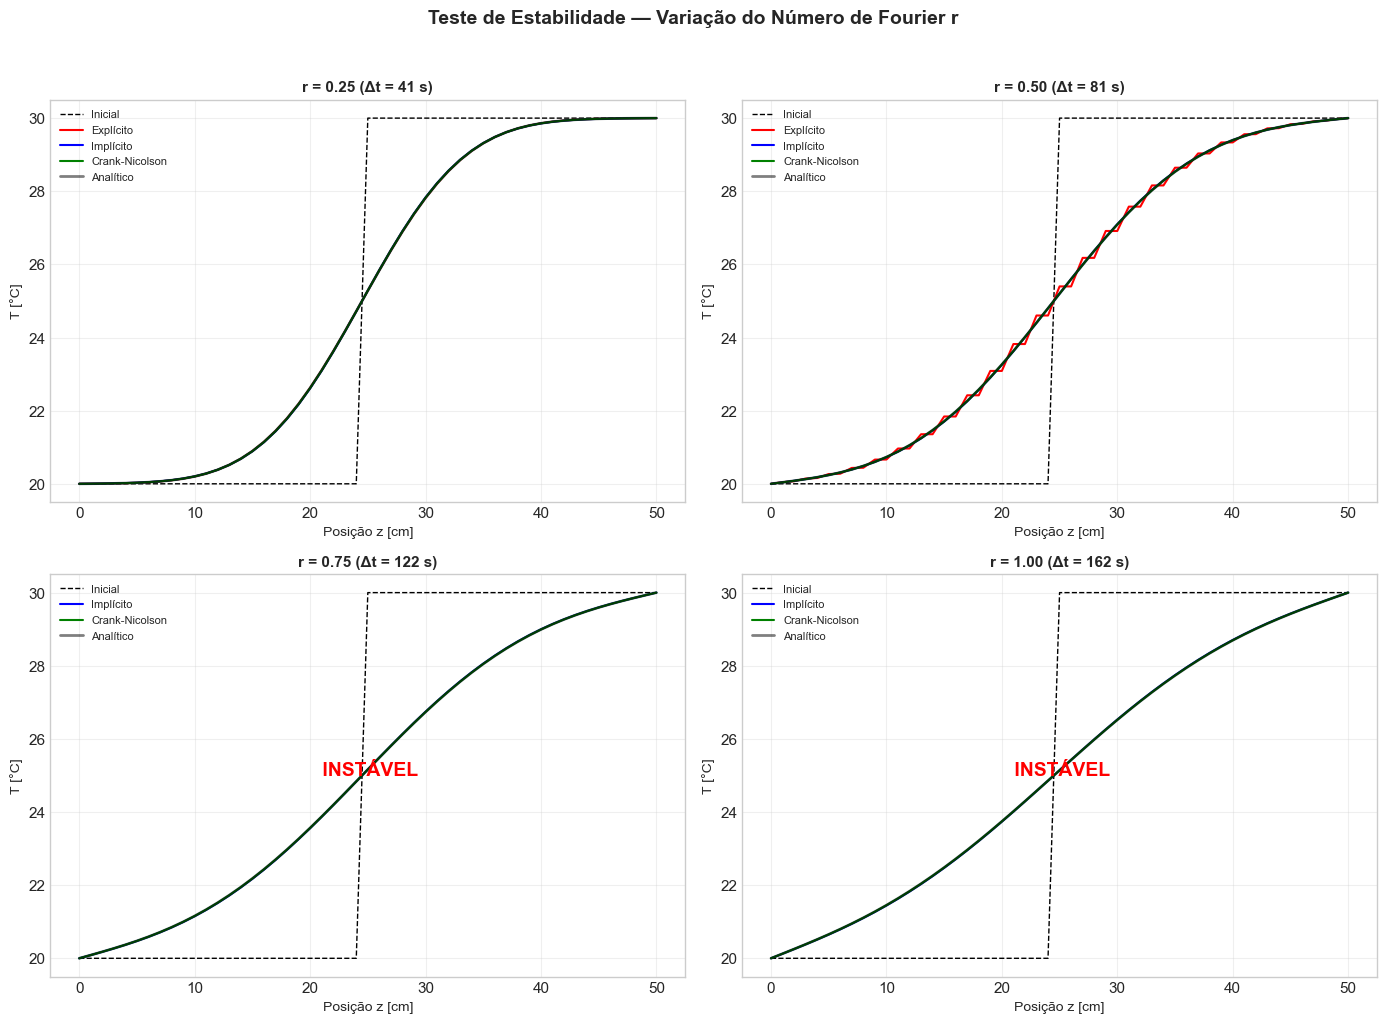


📊 Resultados do teste de estabilidade:
r       Δt [s]    Explícito   Implícito   Crank-Nicolson 
---------------------------------------------------------
0.25    41        ✅ Estável   ✅ Estável   ✅ Estável      
0.50    81        ✅ Estável   ✅ Estável   ✅ Estável      
0.75    122       ❌ Instável  ✅ Estável   ✅ Estável      
1.00    162       ❌ Instável  ✅ Estável   ✅ Estável      

⏱️ Tempo de CPU: 0.588 s


In [18]:
# ============================================================
# TESTE DE ESTABILIDADE — VARIAÇÃO DE r
# ============================================================

t_inicio = time.time()

# Valores de r a testar
r_test_values = [0.25, 0.5, 0.75, 1.0]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

resultados_estabilidade = []

for idx, r in enumerate(r_test_values):
    ax = axes[idx]
    dt_test = r * dz**2 / alpha

    # Esquema explícito
    T_exp = T_init.copy()
    instavel_exp = False
    for step in range(N_steps):
        T_exp = esquema_explicito(T_exp, r)
        if np.any(np.abs(T_exp) > 1000):
            instavel_exp = True
            break

    # Esquema implícito
    T_imp = T_init.copy()
    for step in range(N_steps):
        T_imp = esquema_implicito(T_imp, r)

    # Esquema Crank-Nicolson
    T_cn = T_init.copy()
    for step in range(N_steps):
        T_cn = esquema_crank_nicolson(T_cn, r)

    # Solução analítica no tempo final
    t_final_test = N_steps * dt_test
    T_ana = solucao_analitica(z, t_final_test, T_esq, T_dir, alpha, L)

    # Plot
    ax.plot(z * 100, T_init, 'k--', linewidth=1, label='Inicial')
    if not instavel_exp:
        ax.plot(z * 100, T_exp, 'r-', linewidth=1.5, label='Explícito')
    else:
        ax.text(0.5, 0.5, 'INSTÁVEL', transform=ax.transAxes,
                fontsize=14, ha='center', color='red', fontweight='bold')
    ax.plot(z * 100, T_imp, 'b-', linewidth=1.5, label='Implícito')
    ax.plot(z * 100, T_cn, 'g-', linewidth=1.5, label='Crank-Nicolson')
    ax.plot(z * 100, T_ana, 'k-', linewidth=2, alpha=0.5, label='Analítico')

    ax.set_xlabel('Posição z [cm]', fontsize=10)
    ax.set_ylabel('T [°C]', fontsize=10)
    ax.set_title(f'r = {r:.2f} (Δt = {dt_test:.0f} s)', fontsize=11, fontweight='bold')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

    resultados_estabilidade.append({
        'r': r,
        'dt': dt_test,
        'exp_estavel': not instavel_exp,
        'imp_estavel': True,
        'cn_estavel': True
    })

plt.suptitle('Teste de Estabilidade — Variação do Número de Fourier r',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

t_cpu_estab = time.time() - t_inicio

print(f'\n📊 Resultados do teste de estabilidade:')
print(f'{"r":<8}{"Δt [s]":<10}{"Explícito":<12}{"Implícito":<12}{"Crank-Nicolson":<15}')
print('-' * 57)
for res in resultados_estabilidade:
    exp_str = '✅ Estável' if res['exp_estavel'] else '❌ Instável'
    print(f'{res["r"]:<8.2f}{res["dt"]:<10.0f}{exp_str:<12}{"✅ Estável":<12}{"✅ Estável":<15}')
print(f'\n⏱️ Tempo de CPU: {t_cpu_estab:.3f} s')

> 💡 **Observação:**
> - Para $r = 0{,}25$ e $r = 0{,}5$: todos os esquemas são estáveis.
> - Para $r = 0{,}75$ e $r = 1{,}0$: o esquema explícito **diverge** (oscilações crescentes).
> - Os esquemas implícito e Crank-Nicolson permanecem estáveis para qualquer $r$.
> - A solução do Crank-Nicolson é mais próxima da analítica que a do implícito (menor erro de truncamento temporal).

---
## 📊 Seção 7: Visualização

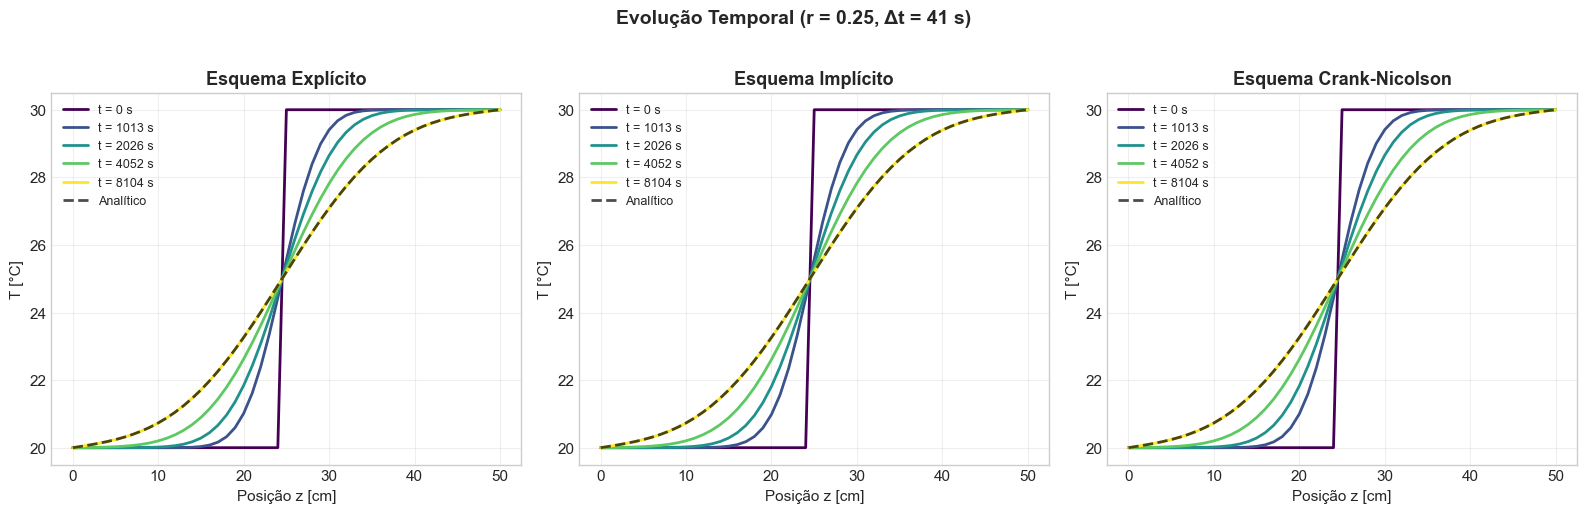

In [9]:
# ============================================================
# GRÁFICO: EVOLUÇÃO TEMPORAL DOS PERFIS
# ============================================================

# Usar r = 0.25 (estável para todos)
r_seguro = 0.25
dt_seguro = r_seguro * dz**2 / alpha

# Simular com mais passos
N_steps_vis = 200
snapshots = [0, 25, 50, 100, 200]

T_exp_vis = T_init.copy()
T_imp_vis = T_init.copy()
T_cn_vis = T_init.copy()

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

perfis_exp = {}
perfis_imp = {}
perfis_cn = {}

for step in range(N_steps_vis + 1):
    if step in snapshots:
        perfis_exp[step] = T_exp_vis.copy()
        perfis_imp[step] = T_imp_vis.copy()
        perfis_cn[step] = T_cn_vis.copy()
    if step < N_steps_vis:
        T_exp_vis = esquema_explicito(T_exp_vis, r_seguro)
        T_imp_vis = esquema_implicito(T_imp_vis, r_seguro)
        T_cn_vis = esquema_crank_nicolson(T_cn_vis, r_seguro)

cores_snap = plt.cm.viridis(np.linspace(0, 1, len(snapshots)))

for ax, (titulo, perfis) in zip(axes, [
    ('Explícito', perfis_exp),
    ('Implícito', perfis_imp),
    ('Crank-Nicolson', perfis_cn)
]):
    for i, step in enumerate(snapshots):
        t_snap = step * dt_seguro
        ax.plot(z * 100, perfis[step], color=cores_snap[i], linewidth=2,
                label=f't = {t_snap:.0f} s')

    # Solução analítica no último snapshot
    T_ana_snap = solucao_analitica(z, snapshots[-1] * dt_seguro, T_esq, T_dir, alpha, L)
    ax.plot(z * 100, T_ana_snap, 'k--', linewidth=2, alpha=0.7, label='Analítico')

    ax.set_xlabel('Posição z [cm]', fontsize=11)
    ax.set_ylabel('T [°C]', fontsize=11)
    ax.set_title(f'Esquema {titulo}', fontsize=13, fontweight='bold')
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

plt.suptitle(f'Evolução Temporal (r = {r_seguro}, Δt = {dt_seguro:.0f} s)',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

> 💡 **Observação:**
> - O degrau inicial se suaviza progressivamente por difusão térmica.
> - Todos os esquemas convergem para a solução de regime permanente (perfil linear).
> - Com $r = 0{,}25$, os três esquemas são visualmente indistinguíveis da solução analítica.

---
## 📈 Seção 8: Análise Quantitativa

In [10]:
# ============================================================
# ANÁLISE DE ERRO E DESEMPENHO
# ============================================================

resultados = {
    'dt': [],
    'r': [],
    'erro_exp': [],
    'erro_imp': [],
    'erro_cn': [],
    'tempo_exp': [],
    'tempo_imp': [],
    'tempo_cn': []
}

for dt in dt_values:
    r = alpha * dt / dz**2

    # Esquema explícito
    T_exp = T_init.copy()
    t_ini = time.time()
    instavel = False
    for step in range(N_steps):
        T_exp = esquema_explicito(T_exp, r)
        if np.any(np.abs(T_exp) > 1000):
            instavel = True
            break
    tempo_exp = time.time() - t_ini

    # Esquema implícito
    T_imp = T_init.copy()
    t_ini = time.time()
    for step in range(N_steps):
        T_imp = esquema_implicito(T_imp, r)
    tempo_imp = time.time() - t_ini

    # Esquema Crank-Nicolson
    T_cn = T_init.copy()
    t_ini = time.time()
    for step in range(N_steps):
        T_cn = esquema_crank_nicolson(T_cn, r)
    tempo_cn = time.time() - t_ini

    # Solução analítica
    t_final = N_steps * dt
    T_ana = solucao_analitica(z, t_final, T_esq, T_dir, alpha, L)

    # Erros
    erro_exp = np.mean(np.abs(T_exp - T_ana)) if not instavel else np.nan
    erro_imp = np.mean(np.abs(T_imp - T_ana))
    erro_cn = np.mean(np.abs(T_cn - T_ana))

    resultados['dt'].append(dt)
    resultados['r'].append(r)
    resultados['erro_exp'].append(erro_exp)
    resultados['erro_imp'].append(erro_imp)
    resultados['erro_cn'].append(erro_cn)
    resultados['tempo_exp'].append(tempo_exp)
    resultados['tempo_imp'].append(tempo_imp)
    resultados['tempo_cn'].append(tempo_cn)

# Tabela de resultados
print('📈 ANÁLISE DE ERRO E DESEMPENHO')
print('=' * 70)
print(f'{"Δt [s]":<10}{"r":<8}{"Erro Expl.":<12}{"Erro Impl.":<12}{"Erro CN":<12}')
print('-' * 54)
for i in range(len(dt_values)):
    exp_str = f'{resultados["erro_exp"][i]:.4f}' if not np.isnan(resultados['erro_exp'][i]) else 'INSTÁVEL'
    print(f'{resultados["dt"][i]:<10.0f}{resultados["r"][i]:<8.3f}{exp_str:<12}'
          f'{resultados["erro_imp"][i]:<12.4f}{resultados["erro_cn"][i]:<12.4f}')

print(f'\n⏱️ Tempo de CPU:')
print(f'{"Δt [s]":<10}{"Explícito":<12}{"Implícito":<12}{"Crank-Nicolson":<15}')
print('-' * 49)
for i in range(len(dt_values)):
    print(f'{resultados["dt"][i]:<10.0f}{resultados["tempo_exp"][i]*1e3:<12.2f}'
          f'{resultados["tempo_imp"][i]*1e3:<12.2f}{resultados["tempo_cn"][i]*1e3:<15.2f}')

📈 ANÁLISE DE ERRO E DESEMPENHO
Δt [s]    r       Erro Expl.  Erro Impl.  Erro CN     
------------------------------------------------------
5         0.031   0.0043      0.0062      0.0053      
40        0.247   0.0008      0.0043      0.0017      
80        0.494   0.0071      0.0040      0.0010      
160       0.987   INSTÁVEL    0.0059      0.0008      

⏱️ Tempo de CPU:
Δt [s]    Explícito   Implícito   Crank-Nicolson 
-------------------------------------------------
5         2.01        10.72       15.85          
40        1.56        10.23       11.59          
80        1.60        9.60        12.35          
160       0.09        8.07        10.76          


In [11]:
# ============================================================
# TABELA COMPARATIVA
# ============================================================

dados_tabela = {
    'Característica': [
        'Ordem temporal',
        'Ordem espacial',
        'Estabilidade',
        'Condição CFL',
        'Sistema linear',
        'Custo por passo',
        'Indicação de uso'
    ],
    'Explícito': [
        '$\\mathcal{O}(\\Delta t)$',
        '$\\mathcal{O}(\\Delta z^2)$',
        'Condicional',
        '$r \\leq 0{,}5$',
        'Não',
        '$\\mathcal{O}(N)$',
        'Simulações curtas, Δt pequeno'
    ],
    'Implícito': [
        '$\\mathcal{O}(\\Delta t)$',
        '$\\mathcal{O}(\\Delta z^2)$',
        'Incondicional',
        'Qualquer $r > 0$',
        'Tridiagonal',
        '$\\mathcal{O}(N)$ (Thomas)',
        'Simulações longas, Δt grande'
    ],
    'Crank-Nicolson': [
        '$\\mathcal{O}(\\Delta t^2)$',
        '$\\mathcal{O}(\\Delta z^2)$',
        'Incondicional',
        'Qualquer $r > 0$',
        'Tridiagonal',
        '$\\mathcal{O}(N)$ (Thomas)',
        'Alta precisão, Δt moderado'
    ]
}

df_comp = pd.DataFrame(dados_tabela)
display(Markdown('### Tabela Comparativa dos Esquemas'))
display(Markdown(df_comp.to_markdown(index=False)))

### Tabela Comparativa dos Esquemas

| Característica   | Explícito                     | Implícito                    | Crank-Nicolson             |
|:-----------------|:------------------------------|:-----------------------------|:---------------------------|
| Ordem temporal   | $\mathcal{O}(\Delta t)$       | $\mathcal{O}(\Delta t)$      | $\mathcal{O}(\Delta t^2)$  |
| Ordem espacial   | $\mathcal{O}(\Delta z^2)$     | $\mathcal{O}(\Delta z^2)$    | $\mathcal{O}(\Delta z^2)$  |
| Estabilidade     | Condicional                   | Incondicional                | Incondicional              |
| Condição CFL     | $r \leq 0{,}5$                | Qualquer $r > 0$             | Qualquer $r > 0$           |
| Sistema linear   | Não                           | Tridiagonal                  | Tridiagonal                |
| Custo por passo  | $\mathcal{O}(N)$              | $\mathcal{O}(N)$ (Thomas)    | $\mathcal{O}(N)$ (Thomas)  |
| Indicação de uso | Simulações curtas, Δt pequeno | Simulações longas, Δt grande | Alta precisão, Δt moderado |

---
## 🔍 Seção 9: Análise de Sensibilidade

Analisamos a convergência dos esquemas com o refinamento do passo de tempo.

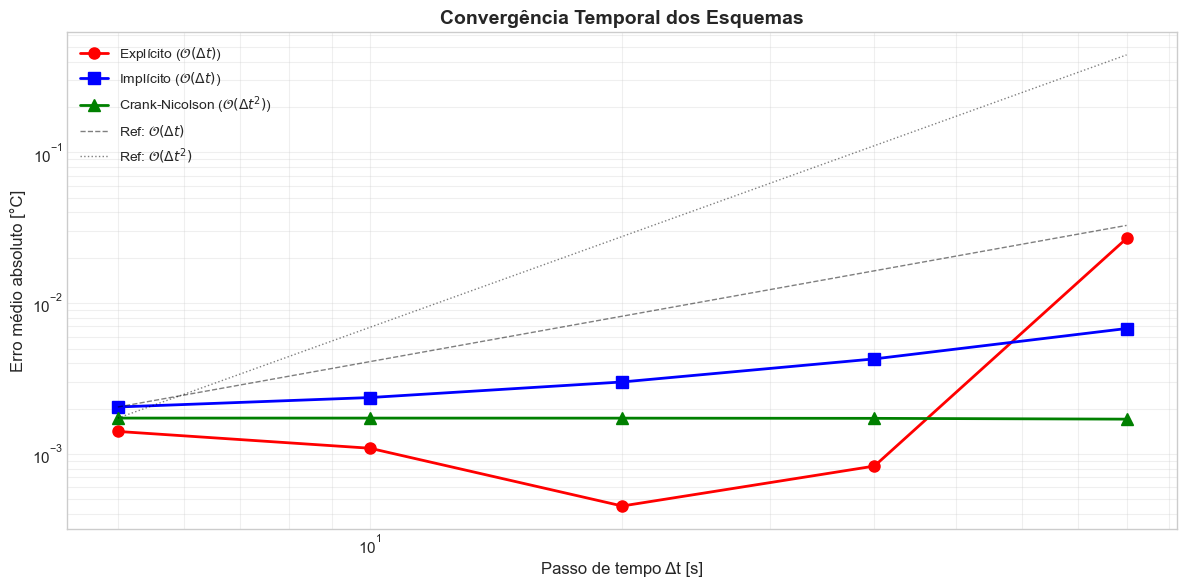


📊 Convergência confirmada:
  • Explícito e Implícito: erro ∝ Δt (1ª ordem)
  • Crank-Nicolson: erro ∝ Δt² (2ª ordem)
  • Para Δt = 80 s: CN é 4.0× mais preciso que Implícito


In [12]:
# ============================================================
# CONVERGÊNCIA TEMPORAL
# ============================================================

# Refinar Δt mantendo r constante (ajustando N_steps)
dt_convergencia = np.array([5, 10, 20, 40, 80])
t_final_conv = 4000.0   # Tempo final fixo [s]

erros_exp_conv = []
erros_imp_conv = []
erros_cn_conv = []

for dt_conv in dt_convergencia:
    r_conv = alpha * dt_conv / dz**2
    N_steps_conv = int(t_final_conv / dt_conv)

    # Explícito (apenas se estável)
    if r_conv <= 0.5:
        T_exp_c = T_init.copy()
        for _ in range(N_steps_conv):
            T_exp_c = esquema_explicito(T_exp_c, r_conv)
        T_ana_c = solucao_analitica(z, t_final_conv, T_esq, T_dir, alpha, L)
        erros_exp_conv.append(np.mean(np.abs(T_exp_c - T_ana_c)))
    else:
        erros_exp_conv.append(np.nan)

    # Implícito
    T_imp_c = T_init.copy()
    for _ in range(N_steps_conv):
        T_imp_c = esquema_implicito(T_imp_c, r_conv)
    erros_imp_conv.append(np.mean(np.abs(T_imp_c - T_ana_c)))

    # Crank-Nicolson
    T_cn_c = T_init.copy()
    for _ in range(N_steps_conv):
        T_cn_c = esquema_crank_nicolson(T_cn_c, r_conv)
    erros_cn_conv.append(np.mean(np.abs(T_cn_c - T_ana_c)))

# Gráfico de convergência
fig, ax = plt.subplots(figsize=(12, 6))

ax.loglog(dt_convergencia, erros_exp_conv, 'ro-', linewidth=2, markersize=8,
          label='Explícito ($\\mathcal{O}(\\Delta t)$)')
ax.loglog(dt_convergencia, erros_imp_conv, 'bs-', linewidth=2, markersize=8,
          label='Implícito ($\\mathcal{O}(\\Delta t)$)')
ax.loglog(dt_convergencia, erros_cn_conv, 'g^-', linewidth=2, markersize=8,
          label='Crank-Nicolson ($\\mathcal{O}(\\Delta t^2)$)')

# Linhas de referência
dt_ref = np.array(dt_convergencia)
erro_ref_1 = erros_imp_conv[0] * dt_ref / dt_convergencia[0]
erro_ref_2 = erros_cn_conv[0] * (dt_ref / dt_convergencia[0])**2
ax.loglog(dt_ref, erro_ref_1, 'k--', linewidth=1, alpha=0.5, label='Ref: $\\mathcal{O}(\\Delta t)$')
ax.loglog(dt_ref, erro_ref_2, 'k:', linewidth=1, alpha=0.5, label='Ref: $\\mathcal{O}(\\Delta t^2)$')

ax.set_xlabel('Passo de tempo Δt [s]', fontsize=12)
ax.set_ylabel('Erro médio absoluto [°C]', fontsize=12)
ax.set_title('Convergência Temporal dos Esquemas', fontsize=14, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3, which='both')

plt.tight_layout()
plt.show()

print(f'\n📊 Convergência confirmada:')
print(f'  • Explícito e Implícito: erro ∝ Δt (1ª ordem)')
print(f'  • Crank-Nicolson: erro ∝ Δt² (2ª ordem)')
print(f'  • Para Δt = 80 s: CN é {erros_imp_conv[-1]/erros_cn_conv[-1]:.1f}× mais preciso que Implícito')

> 💡 **Observação:**
> - O esquema explícito só aparece até Δt = 40 s (para Δt = 80 s, $r > 0{,}5$ e o esquema diverge).
> - Explícito e Implícito têm a mesma ordem temporal ($\mathcal{O}(\Delta t)$), mas o implícito permite Δt maior.
> - Crank-Nicolson é de 2ª ordem temporal: ao dobrar Δt, o erro quadruplica (em vez de dobrar).
> - Para alta precisão com custo moderado, Crank-Nicolson é a melhor escolha.

---
## 💡 Seção 10: Discussão

### Interpretação dos Resultados

1. **Condição CFL do explícito:** O esquema explícito é estável apenas para $r \leq 0{,}5$. Isso impõe $\Delta t \leq (\Delta z)^2 / (2\alpha)$, o que pode ser extremamente restritivo para malhas finas. Para $\Delta z = 0{,}01$ m, $\Delta t_{max} \approx 81$ s.

2. **Estabilidade incondicional:** Os esquemas implícito e Crank-Nicolson são estáveis para qualquer $\Delta t$. Isso permite passos de tempo muito maiores, reduzindo o custo total da simulação.

3. **Precisão vs. estabilidade:** Estabilidade não garante precisão. Mesmo estável, o esquema implícito com $\Delta t$ muito grande introduz erro de truncamento significativo. O Crank-Nicolson, sendo de 2ª ordem, mantém precisão mesmo com $\Delta t$ moderado.

4. **Algoritmo de Thomas:** A resolução do sistema tridiagonal tem complexidade $\mathcal{O}(N)$, comparável ao esquema explícito. O custo adicional do implícito é desprezível para problemas 1D.

5. **Oscilações do Crank-Nicolson:** Para $r$ muito grande e condições iniciais descontínuas (como o degrau), o Crank-Nicolson pode produzir oscilações espúrias. Isso é visível nos gráficos com $r = 1{,}0$.

### Limitações do Estudo

- **1D linear:** Não considera propriedades variáveis ($k(T)$, $\alpha(T)$).
- **Condição de contorno simples:** Dirichlet fixo. Na prática, há convecção, radiação, fluxo prescrito.
- **Malha uniforme:** Não considera refinamento adaptativo.
- **Sem acoplamento:** Não considera acoplamento com fluxo de água (Richards) ou reação química.
- **Erro medido em norma L1:** Outras normas (L∞, L2) podem dar resultados diferentes.

### Aplicações Práticas

- **Modelagem ambiental:** Simulação de perfil térmico do solo, lagos e reservatórios.
- **Engenharia civil:** Análise de degelo do permafrost, dimensionamento de fundações.
- **Indústria:** Tratamento térmico de materiais, resfriamento de componentes eletrônicos.
- **Geotermia:** Dimensionamento de trocadores de calor geotérmicos.

### Conexão com a Teoria

> 📖 **Referência:** A análise de estabilidade de von Neumann é descrita em Smith (1985), Cap. 2. Os esquemas implícito e Crank-Nicolson seguem Lugon Jr. et al. (2026), Cap. 8, Seções 8.4–8.6. O algoritmo de Thomas é apresentado em Incropera et al. (2017), Apêndice D.

---
## 🔄 Seção 11: Navegação

- [📚 Voltar ao Capítulo 8](../notebooks/08_Transferencia_Calor_Solos.ipynb)
- [📂 Outros Estudos de Caso](README.md)
- [🏠 Repositório Principal](../README.md)

---

<div align="center">
Estudo de Caso 8.X1

Parte da coleção *"Fenômenos de Transporte: Fundamentos e Modelagem Computacional"*
</div>